In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, MaxPooling2D, Reshape, Multiply
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.applications import VGG16, VGG19, DenseNet121, ResNet50, MobileNet, InceptionV3, Xception
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

2026-11-05 06:49:22.049528: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793861362.279735      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793861362.346358      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793861362.910027      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793861362.910068      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793861362.910074      23 computation_placer.cc:177] computation placer alr

In [2]:
# Parameters
input_shape = (224, 224, 3)
num_classes = 4
lr = 1e-5
bs = 32
ep = 30

# Define paths
dataset_dir = "/kaggle/input/datasets/blank1508/mendeley-lbc-cervical-cancer"  

print(f"Using dataset directory: {dataset_dir}")
print("Subfolders (classes):", os.listdir(dataset_dir))

# Now define cropped_dirs using the actual class subfolder names
class_subdirs = os.listdir(dataset_dir)  # Should be the 4 class folders
cropped_dirs = {
    subdir: os.path.join(dataset_dir, subdir)
    for subdir in class_subdirs
}

Using dataset directory: /kaggle/input/datasets/blank1508/mendeley-lbc-cervical-cancer
Subfolders (classes): ['High squamous intra-epithelial lesion', 'Low squamous intra-epithelial lesion', 'Negative for Intraepithelial malignancy', 'Squamous cell carcinoma']


In [3]:

import re
def load_images_from_directory(directory, target_size=(224, 224)):
    images, filenames = [], []
    for filename in sorted(os.listdir(directory)):
        img = cv2.imread(os.path.join(directory, filename))
        if img is not None:
            img = cv2.resize(img, target_size)
            images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            filenames.append(filename)
    return np.array(images), filenames

cropped_images, cropped_labels, cropped_groups = {}, {}, {}

for cls, dir_path in cropped_dirs.items():

    images, filenames = load_images_from_directory(dir_path)

    cropped_images[cls] = images
    cropped_labels[cls] = np.full(len(images), cls)

    cropped_groups[cls] = np.array([
        re.match(r'(.+?)\s*\(\d+\)', fn).group(1)
        if re.match(r'(.+?)\s*\(\d+\)', fn)
        else os.path.splitext(fn)[0]
        for fn in filenames
    ])


X_cropped = np.concatenate(list(cropped_images.values()))
y_cropped = np.concatenate(list(cropped_labels.values()))
groups = np.concatenate(list(cropped_groups.values()))

label_to_index = {
    cls: idx for idx, cls in enumerate(cropped_dirs.keys())
}

y_cropped = np.array([
    label_to_index[label] for label in y_cropped
])

y_cropped = to_categorical(y_cropped, num_classes=4)

In [4]:

import numpy as np

y_int = y_cropped.argmax(axis=1)

print("Groups and images per class:\n")

for c in np.unique(y_int):
    idx = y_int == c
    class_groups = np.unique(groups[idx])

    print(f"Class {c}:")
    print(f"  Number of groups: {len(class_groups)}")
    print(f"  Number of images: {np.sum(idx)}")
    print(f"  Group names: {class_groups}")

    for g in class_groups:
        count = np.sum((y_int == c) & (groups == g))
        print(f"    {g}: {count} images")

    print()


Groups and images per class:

Class 0:
  Number of groups: 10
  Number of images: 163
  Group names: ['HSIL_1' 'HSIL_10' 'HSIL_2' 'HSIL_3' 'HSIL_4' 'HSIL_5' 'HSIL_6' 'HSIL_7'
 'HSIL_8' 'HSIL_9']
    HSIL_1: 15 images
    HSIL_10: 19 images
    HSIL_2: 20 images
    HSIL_3: 5 images
    HSIL_4: 17 images
    HSIL_5: 23 images
    HSIL_6: 28 images
    HSIL_7: 15 images
    HSIL_8: 14 images
    HSIL_9: 7 images

Class 1:
  Number of groups: 4
  Number of images: 113
  Group names: ['LSIL_1' 'LSIL_2' 'LSIL_3' 'LSIL_4']
    LSIL_1: 27 images
    LSIL_2: 21 images
    LSIL_3: 28 images
    LSIL_4: 37 images

Class 2:
  Number of groups: 43
  Number of images: 612
  Group names: ['NL_10_' 'NL_11_' 'NL_12_' 'NL_13_' 'NL_14_' 'NL_15_' 'NL_16_' 'NL_17_'
 'NL_18_' 'NL_19_' 'NL_1_' 'NL_20_' 'NL_21_' 'NL_22_' 'NL_23_' 'NL_24_'
 'NL_25_' 'NL_26_' 'NL_27_' 'NL_28_' 'NL_29_' 'NL_2_' 'NL_30_' 'NL_31_'
 'NL_32_' 'NL_33_' 'NL_34_' 'NL_35_' 'NL_36_' 'NL_37_' 'NL_38_' 'NL_39_'
 'NL_3_' 'NL_40_' 'NL_41_' 

In [5]:
import numpy as np

def group_split_per_class(y_int, groups, fractions=(0.80, 0.10, 0.10),
                          trials=1000):

    rng = np.random.default_rng(42)

    unique_groups = np.unique(groups)
    classes = np.unique(y_int)

    group_counts = np.array([
        [np.sum((groups == g) & (y_int == c)) for c in classes]
        for g in unique_groups
    ])

    group_classes = np.argmax(group_counts, axis=1)

    targets = np.array(fractions) * len(y_int)
    class_targets = np.array(fractions)[:, None] * np.bincount(
        y_int, minlength=len(classes)
    )

    best_score = float("inf")
    best_assignment = None

    for _ in range(trials):

        assignment = np.full(len(unique_groups), -1)

        for c in range(len(classes)):
            idx = np.where(group_classes == c)[0]
            idx = rng.permutation(idx)

            # Ensure every class appears in all three splits
            assignment[idx[:3]] = rng.permutation(3)

            # Assign remaining groups randomly
            assignment[idx[3:]] = rng.choice(
                3, size=len(idx) - 3, p=fractions
            )

        split_counts = np.array([
            group_counts[assignment == s].sum(axis=0)
            for s in range(3)
        ])

        split_sizes = split_counts.sum(axis=1)

        size_error = np.sum(((split_sizes - targets) / targets) ** 2)

        class_error = np.sum(
            ((split_counts - class_targets) /
             np.maximum(class_targets, 1)) ** 2
        )

        score = size_error + class_error

        if score < best_score:
            best_score = score
            best_assignment = assignment.copy()

    split_map = dict(zip(unique_groups, best_assignment))

    return np.array([split_map[g] for g in groups])


# Perform splitting
split_id = group_split_per_class(
    y_cropped.argmax(axis=1),
    groups,
    fractions=(0.80, 0.10, 0.10)
)

# Create datasets
X_train, y_train = X_cropped[split_id == 0], y_cropped[split_id == 0]
X_val, y_val = X_cropped[split_id == 1], y_cropped[split_id == 1]
X_test, y_test = X_cropped[split_id == 2], y_cropped[split_id == 2]

# Separate groups
g_train, g_val, g_test = (
    set(groups[split_id == k]) for k in range(3)
)

# Leakage checks
assert not (g_train & g_val)
assert not (g_train & g_test)
assert not (g_val & g_test)

# Print results
for name, X, y, g in [
    ("Train", X_train, y_train, g_train),
    ("Validation", X_val, y_val, g_val),
    ("Test", X_test, y_test, g_test)
]:
    print(f"\n{name}: {len(X)} images / {len(g)} groups")
    print(f"Percentage: {len(X)/len(X_cropped)*100:.2f}%")
    print("Class distribution:", np.sum(y, axis=0))
    print("Groups:", sorted(g))


Train: 739 images / 46 groups
Percentage: 76.82%
Class distribution: [127.  65. 499.  48.]
Groups: [np.str_('HSIL_1'), np.str_('HSIL_2'), np.str_('HSIL_3'), np.str_('HSIL_5'), np.str_('HSIL_6'), np.str_('HSIL_7'), np.str_('HSIL_8'), np.str_('HSIL_9'), np.str_('LSIL_3'), np.str_('LSIL_4'), np.str_('NL_11_'), np.str_('NL_12_'), np.str_('NL_14_'), np.str_('NL_15_'), np.str_('NL_16_'), np.str_('NL_17_'), np.str_('NL_18_'), np.str_('NL_19_'), np.str_('NL_1_'), np.str_('NL_20_'), np.str_('NL_21_'), np.str_('NL_22_'), np.str_('NL_23_'), np.str_('NL_26_'), np.str_('NL_27_'), np.str_('NL_29_'), np.str_('NL_2_'), np.str_('NL_31_'), np.str_('NL_32_'), np.str_('NL_33_'), np.str_('NL_34_'), np.str_('NL_35_'), np.str_('NL_36_'), np.str_('NL_37_'), np.str_('NL_38_'), np.str_('NL_39_'), np.str_('NL_40_'), np.str_('NL_42_'), np.str_('NL_43_'), np.str_('NL_4_'), np.str_('NL_5_'), np.str_('NL_7_'), np.str_('NL_8_'), np.str_('NL_9_'), np.str_('scc_1'), np.str_('scc_2')]

Validation: 109 images / 7 groups

In [6]:
# Data augmentation
datagen = ImageDataGenerator(
    rotation_range=20,         # Random rotation up to 20 degrees
    zoom_range=[0.8, 1.0],     # Zoom out by up to 20%
    brightness_range=[0.9, 1.1],  
    horizontal_flip=True,
    vertical_flip=True,
    preprocessing_function=lambda x: tf.image.adjust_contrast(x, np.random.uniform(0.9, 1.1)),  # Custom contrast adjustment
    fill_mode='nearest'
)

# Fit the generator to the training data
datagen.fit(X_train)

In [7]:
class ASCFBlock(tf.keras.layers.Layer):
    def __init__(self, num_clusters, **kwargs):
        super(ASCFBlock, self).__init__(**kwargs)
        self.num_clusters = num_clusters
        self.conv1x1 = tf.keras.layers.Conv2D(1, kernel_size=1, use_bias=False)
        self.dense = tf.keras.layers.Dense(num_clusters, activation='sigmoid')

    def call(self, feature_maps):
        batch_size = tf.shape(feature_maps)[0]
        h, w, num_channels = feature_maps.shape[1:]
        maps_per_cluster = num_channels // self.num_clusters
        
        reshaped = tf.reshape(feature_maps, (batch_size, h, w, self.num_clusters, maps_per_cluster))
        temp_batch = batch_size * self.num_clusters
        conv_input = tf.reshape(reshaped, (temp_batch, h, w, maps_per_cluster))
        
        fused = self.conv1x1(conv_input)
        fused = tf.reshape(fused, (batch_size, h, w, self.num_clusters))
        
        squeezed = tf.reduce_mean(fused, axis=[1, 2])
        weights = self.dense(squeezed)
        weighted = fused * tf.reshape(weights, (batch_size, 1, 1, self.num_clusters))
        
        final_map = tf.reduce_max(weighted, axis=-1, keepdims=True)
        vector_output = tf.reduce_mean(weighted, axis=[1, 2])
        
        return final_map, vector_output

    def compute_output_spec(self, input_spec):
        batch_size, h, w, num_channels = input_spec.shape
        if num_channels % self.num_clusters != 0:
            raise ValueError(f"Number of channels ({num_channels}) must be divisible by num_clusters ({self.num_clusters})")
        
        final_map_spec = tf.keras.KerasTensor(shape=(batch_size, h, w, 1), dtype=tf.float32)
        vector_output_spec = tf.keras.KerasTensor(shape=(batch_size, self.num_clusters), dtype=tf.float32)
        return final_map_spec, vector_output_spec



def se_block(x, ratio=16):
    channels = x.shape[-1]
    se = GlobalAveragePooling2D()(x)
    se = Dense(channels // ratio, activation='relu')(se)
    se = Dense(channels, activation='sigmoid')(se)
    se = Reshape((1, 1, channels))(se)
    return Multiply()([x, se])

In [8]:
input_layer = Input(shape=input_shape)

# Load pretrained InceptionV3 base model (without top layers)
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Pass the input_layer to the base model
x = base_model(input_layer)

x = Conv2D(1024, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((1, 1))(x)

x = Conv2D(2048, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = se_block(x)
x = MaxPooling2D((1, 1))(x)

# Global Average Pooling
# x = GlobalAveragePooling2D()(x)
ascf_layer = ASCFBlock(num_clusters=16)  # Set visualize=True to see feature maps during training
_, x = ascf_layer(x)

# Additional Dense Layers
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)

# Output Layer
output_layer = Dense(num_classes, activation='softmax')(x)

# Define and compile the model
model = Model(inputs=input_layer, outputs=output_layer)
model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

I0000 00:00:1793861613.552365      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793861613.555100      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_v3        │ (None, 5, 5,      │ 21,802,784 │ input_layer[0][0] │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_94 (Conv2D)  │ (None, 5, 5,      │ 18,875,392 │ inception_v3[0][… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 5, 5,      │      4,096 │ conv2d_94[0][0]   │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 5, 5,      │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_95 (Conv2D)  │ (None, 5, 5,      │ 18,876,416 │ max_pooling2d_4[… │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 5, 5,      │      8,192 │ conv2d_95[0][0]   │
│ (BatchNormalizatio… │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 2048)      │    264,192 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1,      │          0 │ dense_1[0][0]     │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 5, 5,      │          0 │ batch_normalizat… │
│                     │ 2048)             │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 5, 5,      │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ascf_block          │ [(None, 5, 5, 1), │        400 │ max_pooling2d_5[… │
│ (ASCFBlock)         │ (None, 16)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1024)      │     17,408 │ ascf_block[0][1]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1024)      │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 512)       │    524,800 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 512)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 4)         │      2,052 │ dropout_1[0][0] 

 Total params: 60,638,004 (231.32 MB)

 Trainable params: 60,597,428 (231.16 MB)

 Non-trainable params: 40,576 (158.50 KB)

In [9]:
class_counts = np.sum(y_train, axis=0)           
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(num_classes),
    y=np.argmax(y_train, axis=1)
)

class_weight_dict = dict(enumerate(class_weights))

print("Class counts (train):", class_counts.astype(int))
print("Class weights:", class_weight_dict)

Class counts (train): [127  65 499  48]
Class weights: {0: np.float64(1.454724409448819), 1: np.float64(2.8423076923076924), 2: np.float64(0.37024048096192386), 3: np.float64(3.8489583333333335)}


In [10]:
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=bs),
    validation_data=(X_val, y_val),
    epochs=ep,
    batch_size=bs,
    class_weight=class_weight_dict
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30


I0000 00:00:1793861654.557507      66 service.cc:152] XLA service 0x7d08d0001f90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793861654.557542      66 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793861654.557546      66 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793861661.706460      66 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-11-05 06:54:40.449052: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 06:54:40.598322: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 06:54:41.282038: E external/local_xl

22/24 ━━━━━━━━━━━━━━━━━━━━ 1s 622ms/step - accuracy: 0.3717 - loss: 1.3513

2026-11-05 06:55:39.161726: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 06:55:39.304930: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 06:55:39.546180: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 06:55:39.685002: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


24/24 ━━━━━━━━━━━━━━━━━━━━ 162s 3s/step - accuracy: 0.3741 - loss: 1.3551 - val_accuracy: 0.5046 - val_loss: 1.3837
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 630ms/step - accuracy: 0.5304 - loss: 1.3588 - val_accuracy: 0.4587 - val_loss: 1.3826
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 643ms/step - accuracy: 0.5527 - loss: 1.3151 - val_accuracy: 0.4312 - val_loss: 1.3714
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 636ms/step - accuracy: 0.6260 - loss: 1.3364 - val_accuracy: 0.3761 - val_loss: 1.3572
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 641ms/step - accuracy: 0.7323 - loss: 1.1071 - val_accuracy: 0.5505 - val_loss: 1.2683
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 645ms/step - accuracy: 0.7598 - loss: 0.9417 - val_accuracy: 0.6789 - val_loss: 1.0466
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 634ms/step - accuracy: 0.8211 - loss: 0.6053 - val_accuracy: 0.7982 - val_loss: 0.8166
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 634ms/step - accuracy: 0.8919 - loss: 0.4453 - val_accuracy: 0.8349 

4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step - accuracy: 0.8224 - loss: 0.6190
Test Loss: 0.8472
Test Accuracy: 0.7982


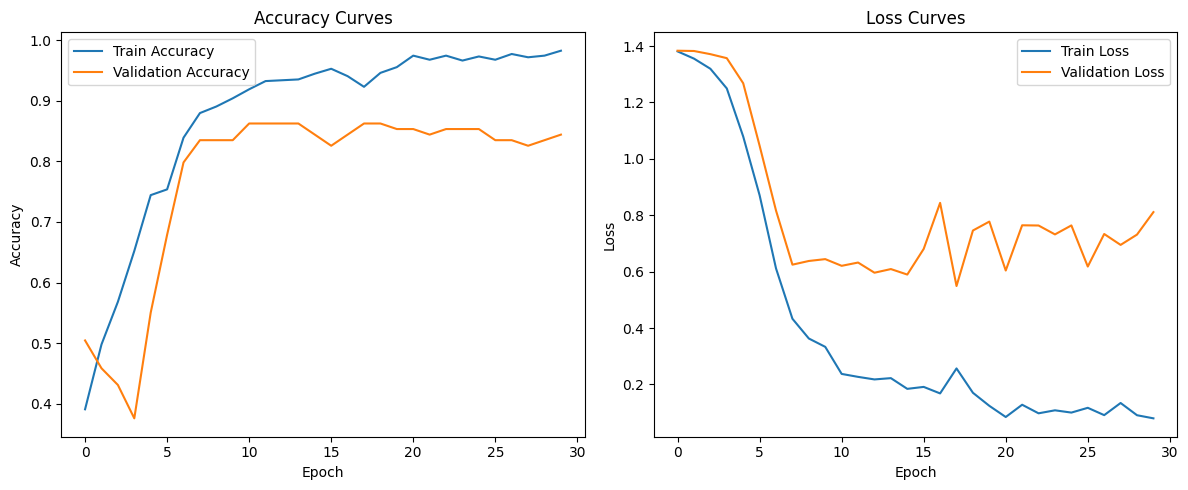

4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step
Classification Report (Test Set):
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.478261  0.578947  0.523810        19
   Low squamous intra-epithelial lesion   0.896552  0.962963  0.928571        27
Negative for Intraepithelial malignancy   0.900000  0.947368  0.923077        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.798246       114
                              macro avg   0.568703  0.622320  0.593864       114
                           weighted avg   0.742051  0.798246  0.768765       114



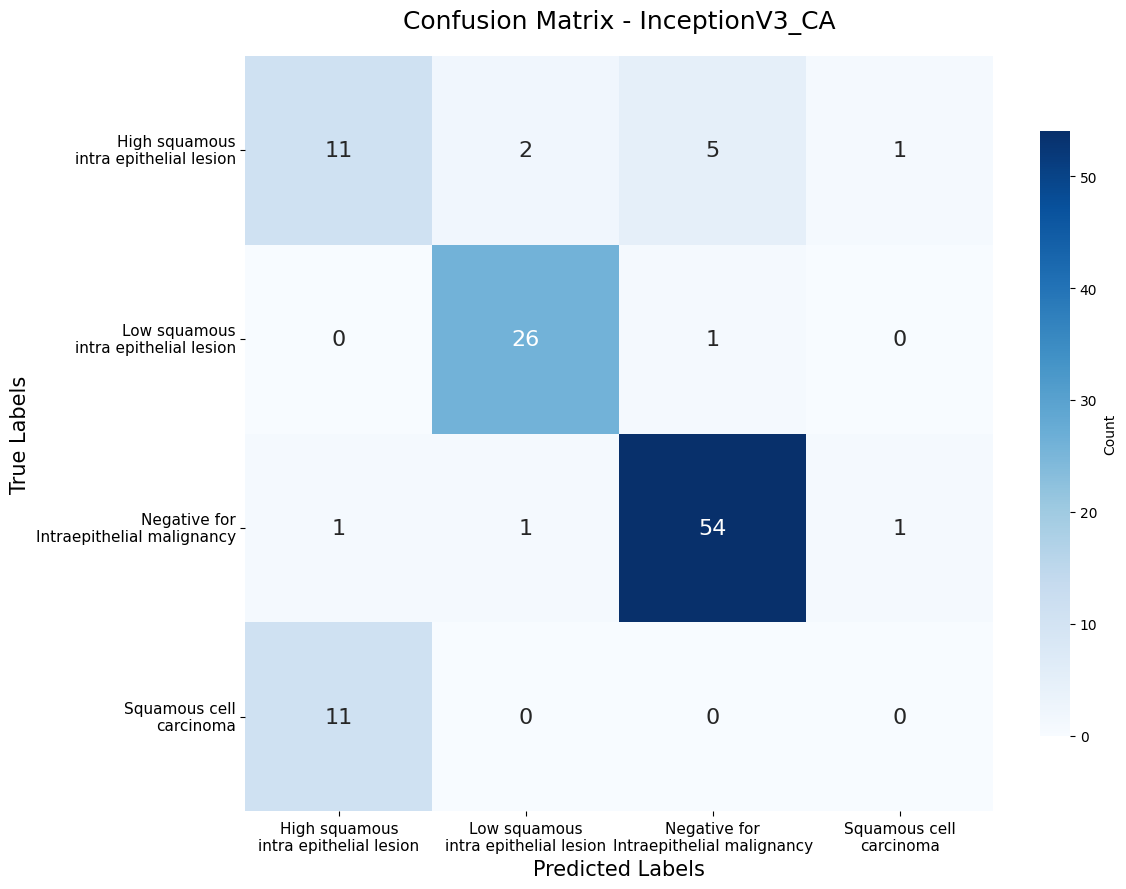

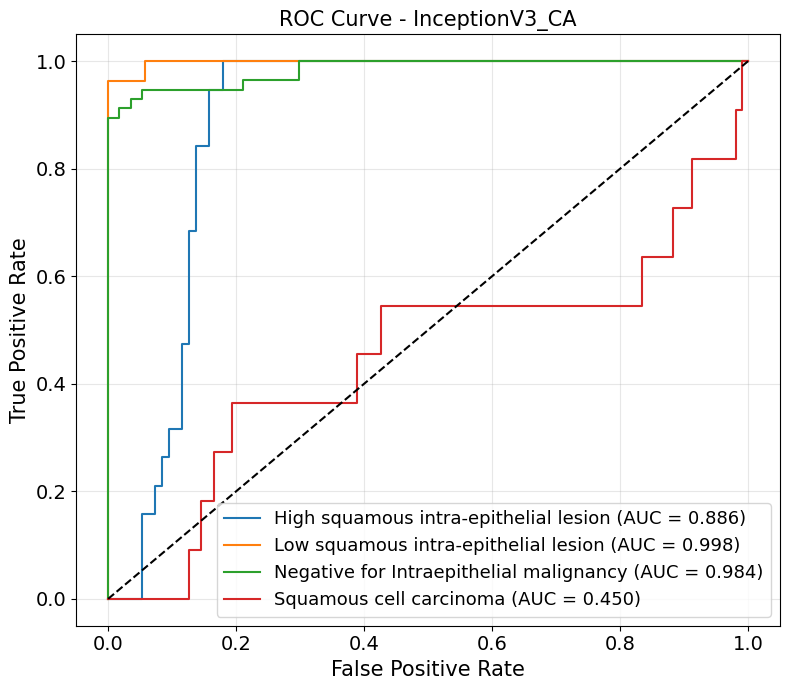

Model saved successfully.


In [11]:
# ===============================
# Final Test Evaluation
# ===============================
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


# ===============================
# Training Curves (Train + Val)
# ===============================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ===============================
# Predictions on TEST set only
# ===============================
y_pred_test = model.predict(X_test, verbose=1)

y_pred_classes = np.argmax(y_pred_test, axis=1)
y_true_classes = np.argmax(y_test, axis=1)


# ===============================
# Classification Report (TEST)
# ===============================
print("Classification Report (Test Set):")
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=list(cropped_dirs.keys()),
        digits=6
    )
)


# ===============================
# Confusion Matrix (TEST)
# ===============================
import textwrap

class_names = list(label_to_index.keys())

# Split each label into exactly two lines
class_names_wrapped = [
    name.replace('_', ' ').replace('-', ' ').split(' ', 2)[0]
    + ' ' +
    name.replace('_', ' ').replace('-', ' ').split(' ', 2)[1]
    + '\n' +
    name.replace('_', ' ').replace('-', ' ').split(' ', 2)[2]
    if len(name.replace('_', ' ').replace('-', ' ').split(' ')) > 2
    else name
    for name in class_names
]

conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(12, 9))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_wrapped,
    yticklabels=class_names_wrapped,
    annot_kws={"size": 16},
    cbar_kws={"label": "Count", "shrink": 0.8}
)

plt.xticks(fontsize=11, rotation=0, ha='center')
plt.yticks(fontsize=11, rotation=0)

plt.xlabel("Predicted Labels", fontsize=15)
plt.ylabel("True Labels", fontsize=15)
plt.title("Confusion Matrix - InceptionV3_CA", fontsize=18, pad=20)

plt.tight_layout()
plt.show()


# ===============================
# ROC Curve & AUC (TEST)
# ===============================
num_classes = y_test.shape[1]
fpr = {}
tpr = {}
roc_auc = {}

class_names = list(label_to_index.keys())          

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 7))   

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})'   
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate',      fontsize=15)
plt.ylabel('True Positive Rate',      fontsize=15)
plt.title('ROC Curve - InceptionV3_CA',      fontsize=15)
plt.legend(loc='lower right', fontsize=13)
plt.grid(True, alpha=0.3)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()


# ===============================
# Save Model
# ===============================
model.save("cervical_cancer_model.h5")
print("Model saved successfully.")

In [12]:
input_layer = Input(shape=input_shape)

# Load pretrained Xception base model (without top layers)
base_model_gap = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Pass the input_layer to the base model
x = base_model_gap(input_layer)

x = Conv2D(1024, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((1, 1))(x)

x = Conv2D(2048, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = se_block(x)
x = MaxPooling2D((1, 1))(x)

# Global Average Pooling
x = GlobalAveragePooling2D()(x)
# ascf_layer = ASCFBlock(num_clusters=16)  # Set visualize=True to see feature maps during training
# _, x = ascf_layer(x)

# Additional Dense Layers
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)

# Output Layer
output_layer = Dense(num_classes, activation='softmax')(x)

# Define and compile the model
model_gap = Model(inputs=input_layer, outputs=output_layer)
model_gap.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
model_gap.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_v3        │ (None, 5, 5,      │ 21,802,784 │ input_layer_2[0]… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_191 (Conv2D) │ (None, 5, 5,      │ 18,875,392 │ inception_v3[0][… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 5, 5,      │      4,096 │ conv2d_191[0][0]  │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 5, 5,      │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_192 (Conv2D) │ (None, 5, 5,      │ 18,876,416 │ max_pooling2d_10… │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 5, 5,      │      8,192 │ conv2d_192[0][0]  │
│ (BatchNormalizatio… │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 2048)      │    264,192 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 1,      │          0 │ dense_7[0][0]     │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 5, 5,      │          0 │ batch_normalizat… │
│ (Multiply)          │ 2048)             │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 5, 5,      │          0 │ multiply_1[0][0]  │
│ (MaxPooling2D)      │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ max_pooling2d_11… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1024)      │  2,098,176 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 1024)      │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 512)       │    524,800 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 512)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 4)         │      2,052 │ dropout_3[0][0] 

 Total params: 62,718,372 (239.25 MB)

 Trainable params: 62,677,796 (239.10 MB)

 Non-trainable params: 40,576 (158.50 KB)

In [13]:
history = model_gap.fit(
    datagen.flow(X_train, y_train, batch_size=bs),
    validation_data=(X_val, y_val),
    epochs=ep,
    batch_size=bs,
    class_weight=class_weight_dict
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.2764 - loss: 1.4766 - val_accuracy: 0.1743 - val_loss: 1.3831
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 637ms/step - accuracy: 0.4063 - loss: 1.1961 - val_accuracy: 0.2661 - val_loss: 1.3495
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 645ms/step - accuracy: 0.5548 - loss: 1.0803 - val_accuracy: 0.4128 - val_loss: 1.3410
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 644ms/step - accuracy: 0.6325 - loss: 0.9575 - val_accuracy: 0.3945 - val_loss: 1.2887
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 639ms/step - accuracy: 0.7050 - loss: 0.7301 - val_accuracy: 0.5229 - val_loss: 1.1700
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 635ms/step - accuracy: 0.7296 - loss: 0.6287 - val_accuracy: 0.6789 - val_loss: 0.9796
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 644ms/step - accuracy: 0.8061 - loss: 0.5072 - val_accuracy: 0.7523 - val_loss: 0.8344
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 646ms/step - accuracy: 0.8566 - loss: 0.3788 - val_accura

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.7653 - loss: 0.6267
Test Loss: 0.8094
Test Accuracy: 0.7544


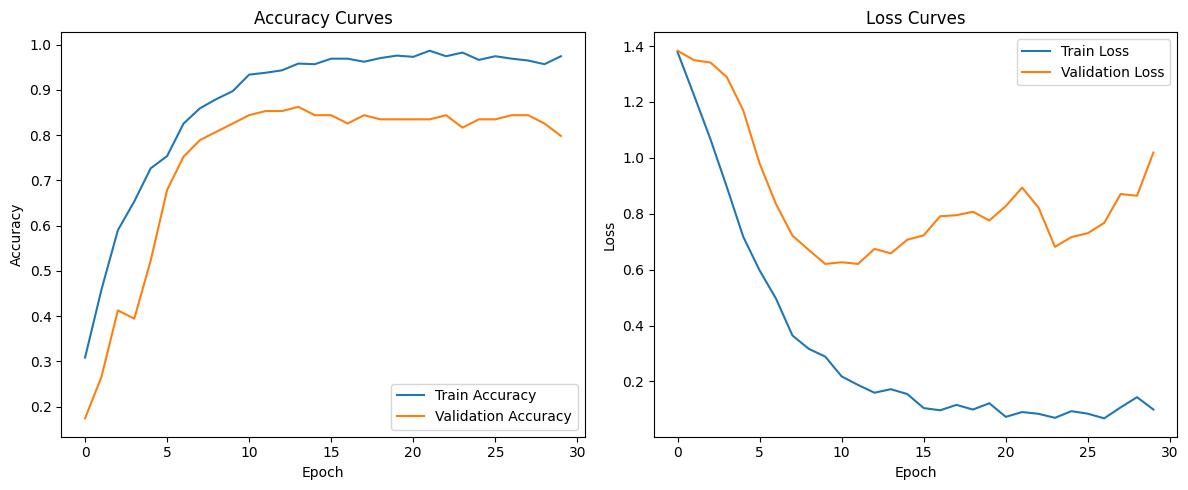

4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step
Classification Report:
                                         precision    recall  f1-score   support

  High squamous intra-epithelial lesion   0.400000  0.526316  0.454545        19
   Low squamous intra-epithelial lesion   0.960000  0.888889  0.923077        27
Negative for Intraepithelial malignancy   0.896552  0.912281  0.904348        57
                Squamous cell carcinoma   0.000000  0.000000  0.000000        11

                               accuracy                       0.754386       114
                              macro avg   0.564138  0.581871  0.570493       114
                           weighted avg   0.742311  0.754386  0.746555       114



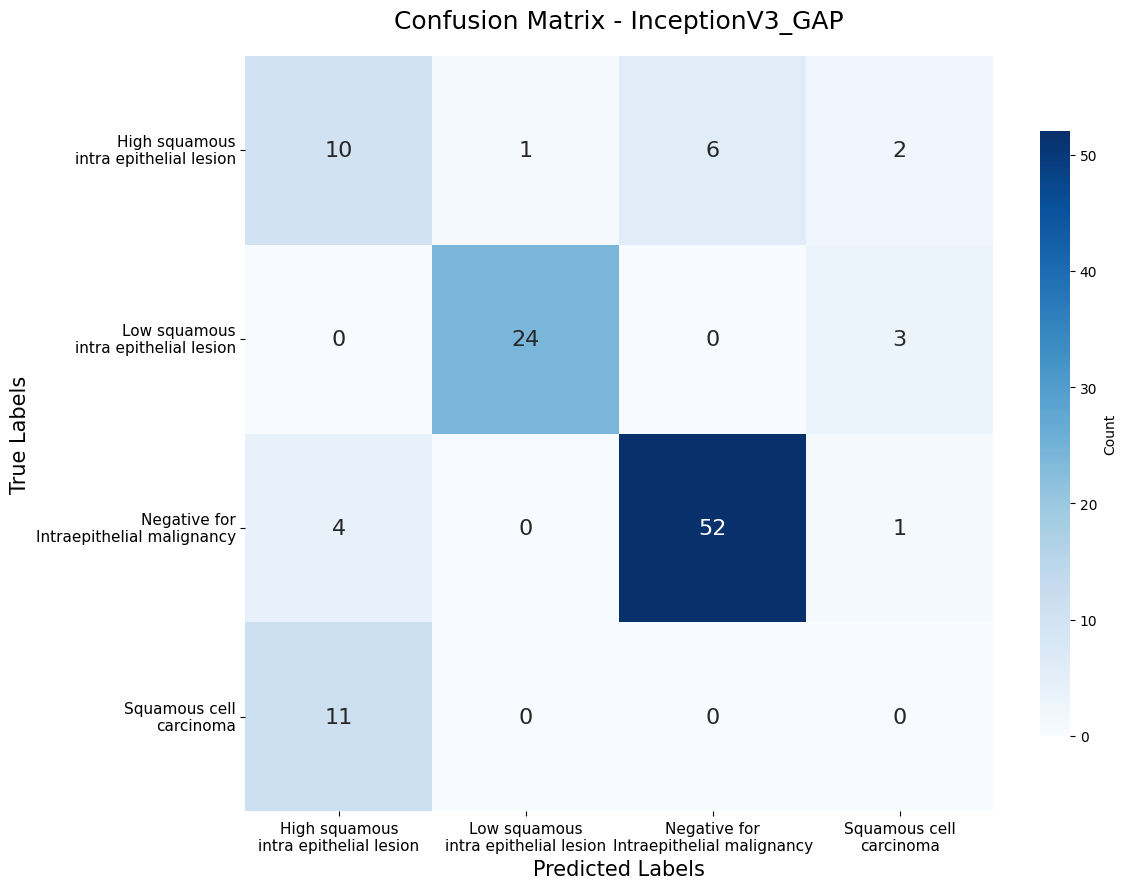

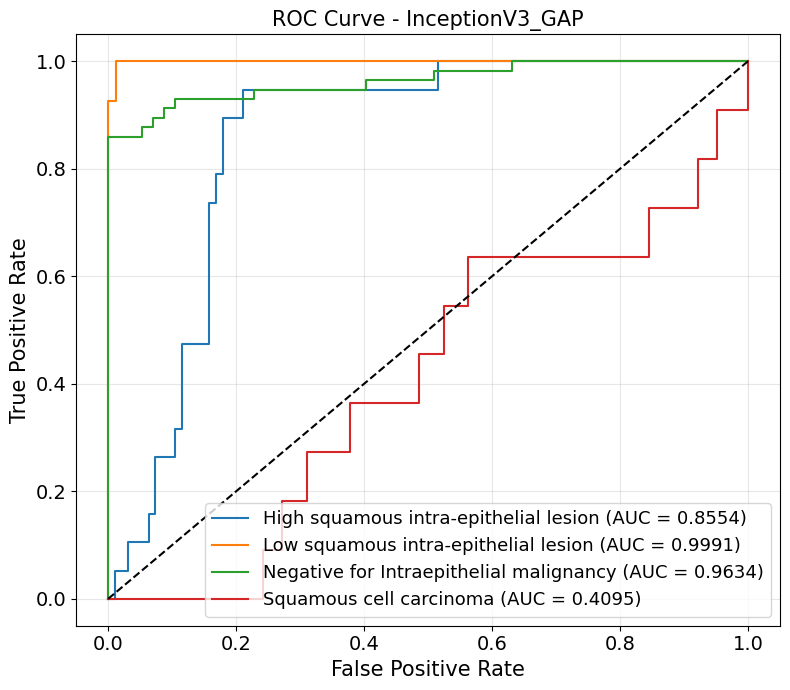

Model saved successfully.


In [14]:
# ===============================
# Final Test Evaluation
# ===============================
test_loss, test_accuracy = model_gap.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


# ===============================
# Training Curves (Train + Val)
# ===============================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ===============================
# Predictions on TEST set only
# ===============================
y_pred_test = model_gap.predict(X_test, verbose=1)

y_pred_classes = np.argmax(y_pred_test, axis=1)
y_true_classes = np.argmax(y_test, axis=1)


# ===============================
# Classification Report (TEST)
# ===============================
print("Classification Report:")
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=list(cropped_dirs.keys()),
        digits=6
    )
)


# ===============================
# Confusion Matrix (TEST)
# ===============================
import textwrap

class_names = list(label_to_index.keys())

# Split each label into exactly two lines
class_names_wrapped = [
    name.replace('_', ' ').replace('-', ' ').split(' ', 2)[0]
    + ' ' +
    name.replace('_', ' ').replace('-', ' ').split(' ', 2)[1]
    + '\n' +
    name.replace('_', ' ').replace('-', ' ').split(' ', 2)[2]
    if len(name.replace('_', ' ').replace('-', ' ').split(' ')) > 2
    else name
    for name in class_names
]

conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(12, 9))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_wrapped,
    yticklabels=class_names_wrapped,
    annot_kws={"size": 16},
    cbar_kws={"label": "Count", "shrink": 0.8}
)

plt.xticks(fontsize=11, rotation=0, ha='center')
plt.yticks(fontsize=11, rotation=0)

plt.xlabel("Predicted Labels", fontsize=15)
plt.ylabel("True Labels", fontsize=15)
plt.title("Confusion Matrix - InceptionV3_GAP", fontsize=18, pad=20)

plt.tight_layout()
plt.show()



# ===============================
# ROC Curve & AUC (TEST)
# ===============================
num_classes = y_test.shape[1]
fpr = {}
tpr = {}
roc_auc = {}

class_names = list(label_to_index.keys())          

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 7))   

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.4f})'   
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate',      fontsize=15)
plt.ylabel('True Positive Rate',      fontsize=15)
plt.title('ROC Curve - InceptionV3_GAP',      fontsize=15)
plt.legend(loc='lower right', fontsize=13)
plt.grid(True, alpha=0.3)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()

# ===============================
# Save Model
# ===============================
model_gap.save("cervical_cancer_model_gap.h5")
print("Model saved successfully.")